# CSE 242 Assignment 2

**3 questions, 100 points**

**AI-use disclosure:** The separate `ai-disclosure-and-transcripts.pdf` describes AI contributions and contains the deidentified readable conversation. Source transcript JSONL files retain available visible messages and tool activity.

## Instruction 

- Submit your assignments onto **Canvas** by the due date. Upload a <code>zip</code> file containing:

    (1) The saved/latest <code>.ipynb</code> file.

    (2) Also save your file into a pdf version, if error appears, save an html version instead (easy to grade for written questions).
    
    (3) All other materials to make your <code>.ipynb</code> file runnable.
    
    **For assignment related questions, please reach TA or grader through EdDiscussion.**
    
- This is an **individual** assignment. All help from others (from the web, books other than text, genAI, or people other than the TA or instructor) must be clearly acknowledged. 
- Most coding parts can be finished with only 1-2 lines of codes.
- Make sure you have installed required packages: <code>scikit-learn</code>.
- Double click to edit each markdown cell.

## Objective 

- **Task 1:** Maximum likelihood estiamtion (math)
- **Task 2:** Linear Regression (with Scikit-learn)
- **Task 3:** Principle Component Analysis (with Scikit-learn)

# Question 1 (Maximum likelihood estiamtion and Posterior, 20 pts) 

Assume we have a coin that has some unknown probability $h$ of coming up heads (and probability $1-h$ of coming up tails). If the coin is flipped five times getting three heads and two tails ($\mathbf{HHHTT}$) then:

(a -- 10pts) What is the maximum likelihood estimate for $h$?

(b -- 10pts) Assume that (before flipping the coin) we have a prior density $p(h)$ for the various values of $h\in [0,1]$. Give the formula for the posterior probability density $p(h \mid \mathbf{HHHTT})$ as a function of the prior $p(h)$.

For Question 1(b), the solution is acceptable if the formula contains an integral.

**Solution (a).** For the ordered outcome $D=\mathrm{HHHTT}$, the likelihood is
$$L(h)=h^3(1-h)^2,\qquad 0\leq h\leq1.$$
For $0<h<1$,
$$\ell(h)=3\log h+2\log(1-h),\qquad
\ell'(h)=\frac3h-\frac2{1-h}.$$
Setting the derivative to zero gives $3(1-h)=2h$, so
$$\boxed{\hat h_{\mathrm{MLE}}=\frac35=0.6.}$$
The second derivative $-3/h^2-2/(1-h)^2$ is negative, and the likelihood is zero at both endpoints. This is the global maximum.

**Solution (b).** Bayes' rule, with the evidence obtained by integrating over the unknown parameter, gives
$$\boxed{p(h\mid D)=\frac{h^3(1-h)^2p(h)}{\displaystyle\int_0^1 u^3(1-u)^2p(u)\,du},\quad 0\leq h\leq1.}$$
The posterior is zero outside $[0,1]$, provided the denominator is positive. This expression allows any proper prior density $p(h)$ with positive evidence. There is no binomial coefficient for the specified ordered sequence; if only the count of heads were observed, its binomial coefficient would cancel in the posterior and leave the same MLE.

# Question 2 (Linear Regression, 40 pts)
In this question, you will be using **Scikit-learn** to empirically apply the Linear Regression model. We will adopt an advertisement dataset **Advertising.csv** from Kaggle. 

### Reading data using Pandas

In [1]:
# All random choices use a fixed seed; input data is shipped beside the notebook.
from pathlib import Path
import platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

SEED = 242
csv_path = Path("Advertising.csv")
if not csv_path.exists():  # Also support execution from the workspace root.
    csv_path = Path("Assignment2") / "Advertising.csv"
data = pd.read_csv(csv_path, index_col=0)
print(f"Python {platform.python_version()} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
data.head()

Python 3.13.12 | NumPy 2.5.3 | pandas 3.1.0 | scikit-learn 1.9.1


,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


**Reproducibility:** The 80/20 split and Gaussian-noise generator both use seed 242. PCA uses full SVD on centered, unscaled pixel intensities. All reported numerical results are generated by the code in this notebook.

In [2]:
data.shape

(200, 4)

### Features and responses

What are the features?
- **TV:** advertising dollars spent on TV for a single product in a given market (in thousands of dollars)
- **Radio:** advertising dollars spent on Radio
- **Newspaper:** advertising dollars spent on Newspaper

What is the response?
- **Sales:** sales of a single product in a given market (in thousands of items)

What else do we know?
- There are 200 **observations**, and each observation (each row) is a single market.
- **Your main task**: predict the sales of a single product in a given market.
- Since the response variable is continuous, this is a **regression** problem.

### Linear regression

**Pros:** fast, no tuning required, highly interpretable

**Cons:** adopting the linear regression is unlikely to always generate the best predictive accuracy, since Linear Regression presumes a linear relationship between the features and response. This assumption may not always make sense. (But if one can _transform_ the features so that do have a linear relationship, sometimes progress can be made, for example by taking logs.)

**Expression:**

- $y$: the response
- $\beta_0$: the intercept
- $\beta_1$: the coefficient for $x_1$ (the first feature)
- $\beta_i$ is the coefficient for $x_i$ (the ith feature, $i\in \{1, 2, ..., n\}$)

For this regression task:

$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$

The $\beta$ values ($\beta=[\beta_0, \beta_1, \beta_2, \beta_3]$) are called the **model coefficients**. These values are "learned" during the model fitting step using the "least squares" criterion. Then, we can make use of the fitted model to make predictions!

### Prepare the dataset for training use

- Scikit-learn expects X (feature matrix) and y (response vector) to be NumPy arrays.
- Pandas is built on top of NumPy, and exposes numpy methods. Thus, X can be a pandas DataFrame, y can be a pandas Series!

In [3]:
# Prepare the feature X
X = data[['TV', 'Radio', 'Newspaper']]

# check the type and shape of X
print(type(X))
print(X.shape)

<class 'pandas.DataFrame'>
(200, 3)


In [4]:
# Prepare the response Y
y = data['Sales']
# check the type and shape of y
print(type(y))
print(y.shape)

<class 'pandas.Series'>
(200,)


## Question 2.1 (Split the dataset into train and test parts, 5 pts)

For features $X$ and response $y$, use **sklearn** to perform the the splitting of dataset: $80\%$ for train data, $20\%$ for the test data.

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

Double check the shape of train and test data:

In [6]:
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

X_train: (160, 3) y_train: (160,)
X_test:  (40, 3) y_test:  (40,)


## Question 2.2 (Train a Linear regression model via Scikit-learn, 10 pts)

Assume you model is named as **model**, and you train the linear regression model to fit on the training data.

In [7]:
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)

In [8]:
print(f"Intercept: {model.intercept_:.4f}")
for name, coefficient in zip(X.columns, model.coef_):
    print(f"{name}: {coefficient:.4f}")

Intercept: 2.6603
TV: 0.0471
Radio: 0.1893
Newspaper: 0.0001


In [9]:
pd.Series(model.coef_, index=X.columns, name="Coefficient (full precision)")

TV           0.047144
Radio        0.189317
Newspaper    0.000055
Name: Coefficient (full precision), dtype: float64

## Question 2.3 (Interpreting model coefficients, 10 pts)

The coefficients of each feature are printed above. 

### Your tasks:

- What is the trained linear regression model? 

- **(replace $\beta_i$ below with the trained coefficients, reserve four decimal places, 5 pts)**

$$\text{Sales} = \beta_0 + \beta_1 \times \text{TV} + \beta_2 \times \text{Radio} + \beta_3 \times \text{Newspaper}$$

- **(Open) question (5 pts)**: how do you interpret the coefficient of **TV** ($\beta_1$)?

The fitted model, with coefficients rounded to four decimal places, is
$$\boxed{\widehat{\mathrm{Sales}}=2.6603+0.0471\,\mathrm{TV}
+0.1893\,\mathrm{Radio}+0.0001\,\mathrm{Newspaper}.}$$
Predictions below use the full-precision fitted coefficients rather than the rounded display values.

Holding Radio and Newspaper spending fixed, an additional **1,000 dollars spent on TV** is associated with a predicted increase of $0.0471436$ thousand items, or about **47.14 items sold**. The coefficient describes an association in this fitted model; it does not establish a causal effect of advertising.

### Making predictions

In [10]:
y_pred = model.predict(X_test)
r2_full = model.score(X_test, y_test)
print(f"Test R^2: {r2_full:.6f}")  # score() is R^2, not classification accuracy.

Test R^2: 0.887523


## Model evaluation metrics for regression

Evaluation metrics for classification problems, such as **accuracy**, are not useful for regression problems. Instead, we need evaluation metrics designed for comparing continuous values.  (Since predictions would hardly ever exactly match the measured quantities.)

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is a popular evaluation metric for regression, which is defined as the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

## Question 2.4 (Evaluate your predictions on test features with RMSE metric, 5 pts)

Hint: you may calculate MSE using scikit-learn, but RMSE is a little bit different from MSE.

In [11]:
from sklearn import metrics
rmse_full = np.sqrt(metrics.mean_squared_error(y_test, y_pred))
print(f"Test RMSE: {rmse_full:.9f} thousand items")

Test RMSE: 1.593350785 thousand items


## Question 2.5 (Does the feature 'Newspaper' help? 10 pts)

Does the feature **Newspaper** contribute or impair the model prediction? Now repeat previous procedure: 

- For features $X$, only select **TV** and **Radio**; response $y$ is unchanged.

- Split the dataset as what you have done before.

- Fit/Train the model on the train data.

- Make predictions on the test data.

- Compute the RMSE of the predictions on the test data.

- **Show your observations!**

**Reminder:** if you use <code>random_state</code> while splitting the dataset, make sure the value of <code>random_state</code> is the same for the two splits. So that the test data only differs in the column of **Newspaper**.

In [12]:
X_reduced = data[["TV", "Radio"]]
X_train_reduced, X_test_reduced, y_train_reduced, y_test_reduced = train_test_split(
    X_reduced, y, test_size=0.2, random_state=SEED
)
model_reduced = LinearRegression().fit(X_train_reduced, y_train_reduced)
y_pred_reduced = model_reduced.predict(X_test_reduced)
rmse_reduced = np.sqrt(metrics.mean_squared_error(y_test_reduced, y_pred_reduced))
print(f"With Newspaper:    RMSE = {rmse_full:.9f}")
print(f"Without Newspaper: RMSE = {rmse_reduced:.9f}")
print(f"RMSE reduction: {rmse_full - rmse_reduced:.9f} thousand items")

With Newspaper:    RMSE = 1.593350785
Without Newspaper: RMSE = 1.593295532
RMSE reduction: 0.000055253 thousand items


### Observations

On the same 40 test markets, the RMSE is **1.593350785** thousand items with Newspaper and **1.593295532** without it. Removing Newspaper improves test RMSE by only **0.000055253** thousand items (about 0.055 items). Newspaper contributes essentially no predictive benefit on this split, and its fitted coefficient is nearly zero. The observed improvement is negligible and does not show that Newspaper is harmful in general. Both models use exactly the same training and test rows; no random seed was selected to favor either result.

# Question 3 (PCA, 40 pts)

In this question, we will explore how PCA helps with reducing the dimensionality through scikit-learn. We will adopt a simple digits dataset contained in scikit-learn.

In [13]:
%matplotlib inline
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 160})

In [14]:
from sklearn.datasets import load_digits
data_digit = load_digits()
data_digit.data.shape

(1797, 64)

As you have seen above, there are 1797 rows and 64 columns in this dataset. Each row denotes the pixel values of an image. Since each image is 8*8 (in pixel), the dimension of each feature is 64. Let's take a look at a few images contained in this dataset.

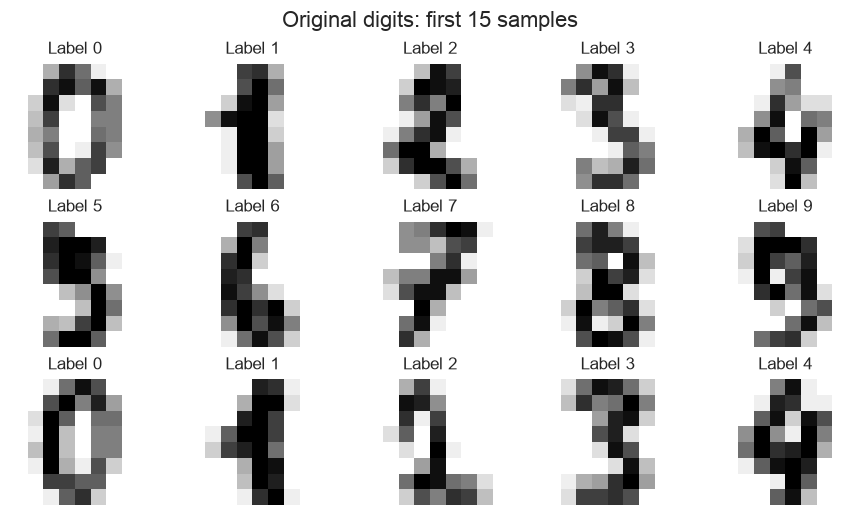

In [15]:
def display_digits(imgs, title):
    """Display the same 15 samples with a fixed grayscale intensity scale."""
    images = np.asarray(imgs).reshape(-1, 8, 8)
    fig, axes = plt.subplots(3, 5, figsize=(7.4, 4.2), layout="constrained")
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap="gray_r", vmin=0, vmax=16,
                  interpolation="nearest")
        ax.set_title(f"Label {data_digit.target[i]}", fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=13)
    plt.show()

display_digits(data_digit.images, "Original digits: first 15 samples")

**PCA** finds uncorrelated orthogonal axes (principal components) in a high dimensional space (i.e., 64) to project the feature onto principal components.

## Question 3.1 (PCA and dimensionality deduction with Scikit-learn, 10 pts)

In this question, you may use the implementation of PCA from scikit-learn, as imported below. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Fit the model with feature X (**data_digit.data** for this dataset) and apply the dimensionality reduction on X, keep 2 components.

In [16]:
from sklearn.decomposition import PCA
pca_2d = PCA(n_components=2, svd_solver="full")
projected = pca_2d.fit_transform(data_digit.data)
print("Original:", data_digit.data.shape)
print("Projected:", projected.shape)

Original: (1797, 64)
Projected: (1797, 2)


With the reduced dimension of features, we can now visualize the projected/reduced features in a 2-dimension plot as below. There are hardly any overlaps between digit 0 and any other digits. While in the central area of the figure, features are not well separable.

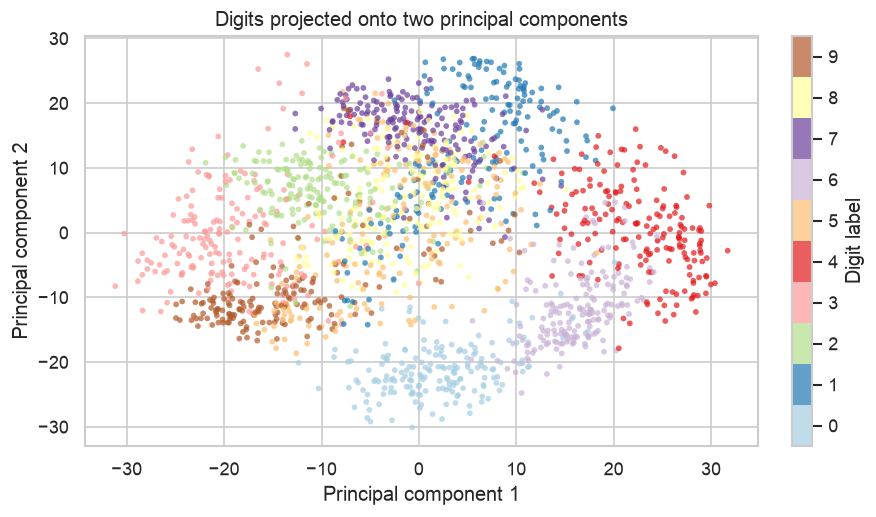

In [17]:
fig, ax = plt.subplots(figsize=(7.2, 4.2), layout="constrained")
scatter = ax.scatter(projected[:, 0], projected[:, 1], c=data_digit.target,
                     s=12, edgecolors="none", alpha=0.7,
                     cmap=plt.colormaps["Paired"].resampled(10),
                     vmin=-0.5, vmax=9.5)
ax.set(xlabel="Principal component 1", ylabel="Principal component 2",
       title="Digits projected onto two principal components")
fig.colorbar(scatter, ax=ax, ticks=range(10), label="Digit label")
plt.show()

## Question 3.2 (How many components do we need? 15 pts)

In practice, suppose you are given a high-dimension dataset, and you are interested in performing a dimension reduciton with PCA. How many conponents do we need? One method is to look at the distribution of the explained variance ratio w.r.t. each component.

In this question, you may use the function <code>explained_variance_ratio</code> in **pca** (with scikit-learn) to address this question. Detailed explanations of parameters settings are available in this [link](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).

### Your task in this question:

Print the ratio of variance explained by each of the selected components;

Visualize with matplotlib or seaborn (x axis: $i-th$ component; y axis: the corresponding ratio of explained variance).

PC1: 0.148905936 (14.8906%)
PC2: 0.136187712 (13.6188%)
Combined: 28.5094%


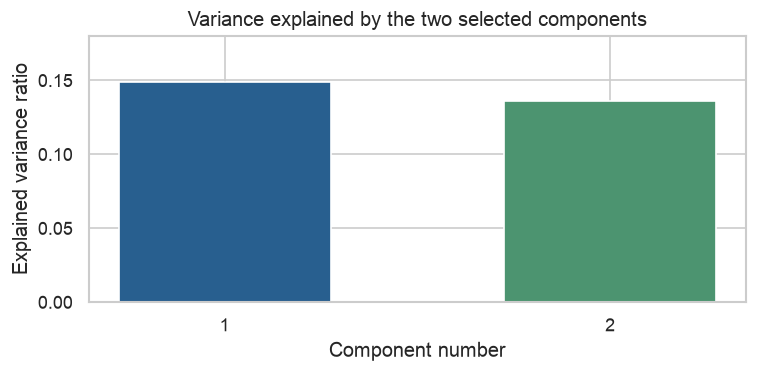

In [18]:
ratios_2d = pca_2d.explained_variance_ratio_
for i, ratio in enumerate(ratios_2d, start=1):
    print(f"PC{i}: {ratio:.9f} ({100 * ratio:.4f}%)")
print(f"Combined: {100 * ratios_2d.sum():.4f}%")

fig, ax = plt.subplots(figsize=(6.2, 3.0), layout="constrained")
ax.bar([1, 2], ratios_2d, width=0.55, color=["#285f8f", "#4c9470"])
ax.set(xticks=[1, 2], xlabel="Component number", ylabel="Explained variance ratio",
       title="Variance explained by the two selected components", ylim=(0, 0.18))
plt.show()

The two selected components explain **14.8906%** and **13.6188%**, respectively, or **28.5094%** together. Two dimensions support visualization but discard most of the variance. To choose a dimension for reconstruction, the full variance spectrum and cumulative ratio below are more informative.

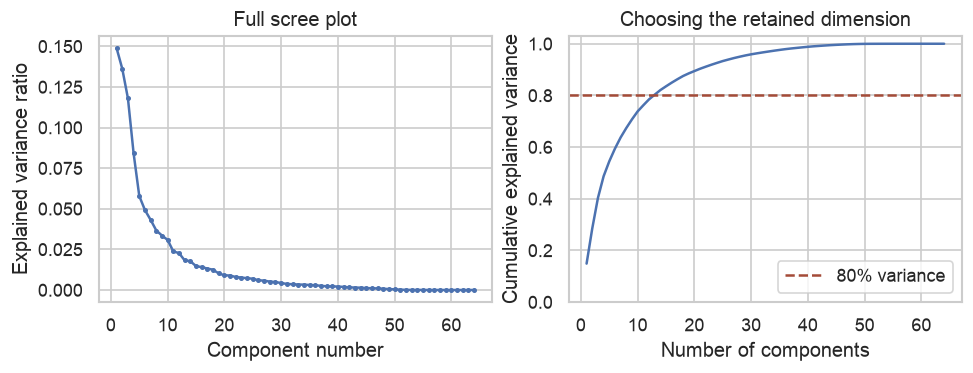

More than 80% variance: 13 components
More than 90% variance: 21 components
More than 95% variance: 29 components


In [19]:
pca_spectrum = PCA(svd_solver="full").fit(data_digit.data)
ratios_all = pca_spectrum.explained_variance_ratio_
cumulative = np.cumsum(ratios_all)
components = np.arange(1, len(ratios_all) + 1)
fig, axes = plt.subplots(1, 2, figsize=(8.0, 3.0), layout="constrained")
axes[0].plot(components, ratios_all, marker=".", markersize=4)
axes[0].set(xlabel="Component number", ylabel="Explained variance ratio", title="Full scree plot")
axes[1].plot(components, cumulative)
axes[1].axhline(0.8, color="#a44b38", linestyle="--", label="80% variance")
axes[1].set(xlabel="Number of components", ylabel="Cumulative explained variance",
            title="Choosing the retained dimension", ylim=(0, 1.03))
axes[1].legend()
plt.show()
for threshold in (0.8, 0.9, 0.95):
    k = np.searchsorted(cumulative, threshold, side="right") + 1
    print(f"More than {threshold:.0%} variance: {k} components")

### How to obtain eigen values and vectors from sklearn PCA

- Eigen values -- <code>your-PCA-model\.explained\_variance\_</code>

- Eigen vectors -- <code>your-PCA-model.components_ </code>

### Eigen vectors (Eigen digits)

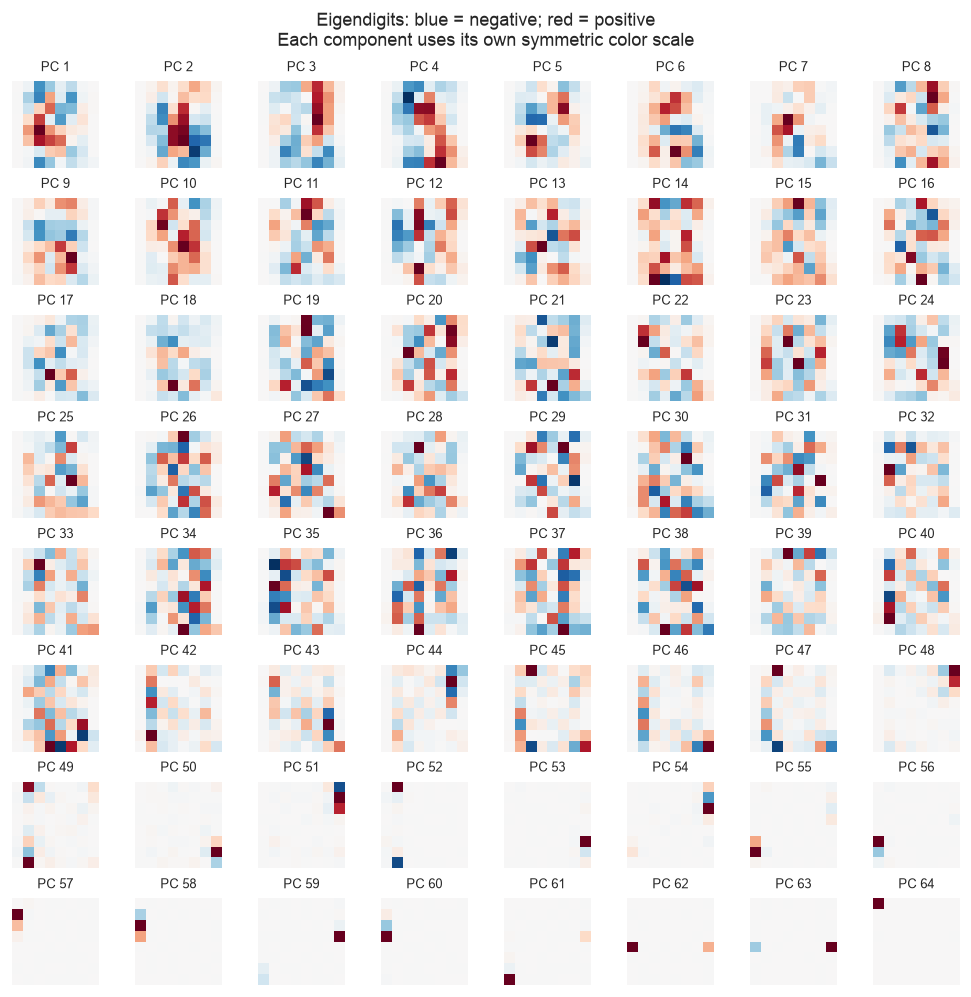

In [20]:
# Each row of components_ is one 64-pixel principal direction.
pca = PCA(svd_solver="full").fit(data_digit.data)
fig, axes = plt.subplots(8, 8, figsize=(8.2, 8.2), layout="constrained")
for idx, ax in enumerate(axes.flat):
    limit = np.abs(pca.components_[idx]).max()
    ax.imshow(pca.components_[idx].reshape(8, 8), cmap="RdBu_r",
              vmin=-limit, vmax=limit, interpolation="nearest")
    ax.set_title(f"PC {idx + 1}", fontsize=8)
    ax.axis("off")
fig.suptitle("Eigendigits: blue = negative; red = positive\nEach component uses its own symmetric color scale", fontsize=11)
plt.show()

## Question 3.3 What are your observations from the visualized eigen vectors? (5 pts)

### Observations

The leading eigendigits show broad, organized patterns of strokes and contrasts across the image, representing the largest variations among the centered digit images. Later directions generally represent finer or lower-variance differences. These are signed pixel weights, rather than examples of particular digit classes, and a component's sign may be reversed without changing PCA.

The final three components explain essentially zero variance: three pixels are constant zero in this dataset, so directions in the covariance null space have no data variation to describe. Their displayed basis vectors can depend on the numerical solver; they should not be interpreted as meaningful digit features. The PCA axes are orthonormal, and their scores are uncorrelated on this fitted dataset. Labels were used only for plotting, not for fitting PCA.

### Feature reconstruction:

Suppose you only want to preserve $80\%$ variance after applying PCA for the dimension reduction, due to storage issues, etc. 

Clean-data components: 13 / 64
Retained variance: 80.289578%


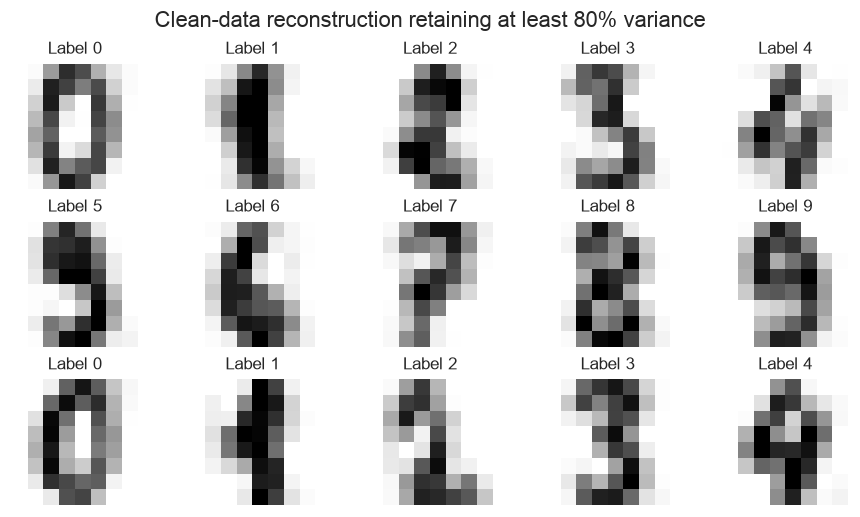

In [21]:
pca_08 = PCA(n_components=0.8, svd_solver="full")
lower_dimension = pca_08.fit_transform(data_digit.data)
reconstructed = pca_08.inverse_transform(lower_dimension)
print(f"Clean-data components: {pca_08.n_components_} / 64")
print(f"Retained variance: {pca_08.explained_variance_ratio_.sum():.6%}")
display_digits(reconstructed, "Clean-data reconstruction retaining at least 80% variance")

Assume now you are given only a set of perturbed images (with some random noise). As shown below, the figures become much more difficult to recognize.

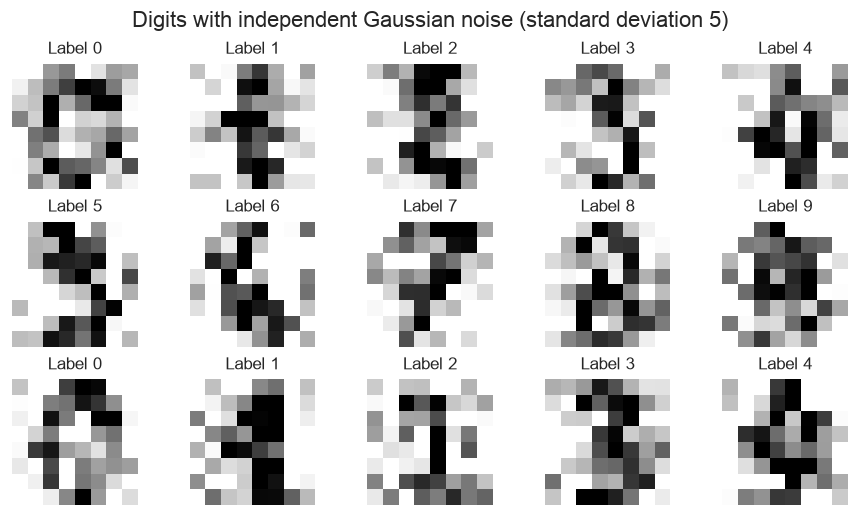

In [22]:
rng = np.random.default_rng(SEED)
noisy_imgs = rng.normal(loc=data_digit.data, scale=5.0)
display_digits(noisy_imgs, "Digits with independent Gaussian noise (standard deviation 5)")

## Question 3.4 Does PCA mitigate the random noise? (10 pts)

### Your tasks:

- Perform feature reconstruction on <code>noisy\_imgs</code> (preserving $80\%$ variance after applying PCA for the dimension reduction)

- Explain your understandings on why PCA reconstructs cleaner images.

Noisy-data components: 40 / 64
Retained noisy variance: 80.116670%


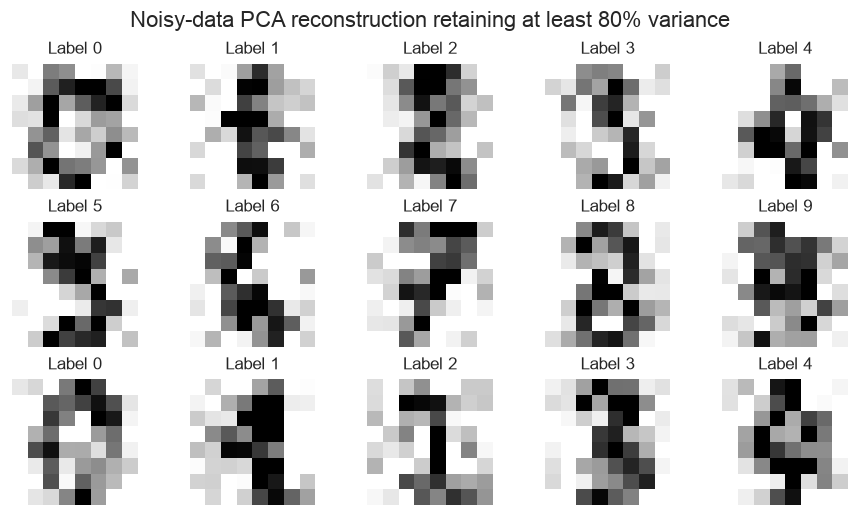

Pixel MSE before PCA: 25.085686
Pixel MSE after PCA:  17.542222
MSE reduction: 30.07%


In [23]:
# Fit only to the noisy images: clean images do not train this PCA model.
pca_noise = PCA(n_components=0.8, svd_solver="full")
projected_noise = pca_noise.fit_transform(noisy_imgs)
reconstructed_noise = pca_noise.inverse_transform(projected_noise)
print(f"Noisy-data components: {pca_noise.n_components_} / 64")
print(f"Retained noisy variance: {pca_noise.explained_variance_ratio_.sum():.6%}")
display_digits(reconstructed_noise, "Noisy-data PCA reconstruction retaining at least 80% variance")

# The clean simulated source is used only to evaluate reconstruction error.
mse_noisy = np.mean((noisy_imgs - data_digit.data) ** 2)
mse_denoised = np.mean((reconstructed_noise - data_digit.data) ** 2)
print(f"Pixel MSE before PCA: {mse_noisy:.6f}")
print(f"Pixel MSE after PCA:  {mse_denoised:.6f}")
print(f"MSE reduction: {100 * (1 - mse_denoised / mse_noisy):.2f}%")

### Explanation

**Yes, PCA reduces the simulated noise here, but does not remove all of it.** The noisy-data model keeps **40 of 64 components**, explaining **80.1167%** of the noisy variance. Against the original clean pixels, mean squared error falls from **25.085686** to **17.542222**, a **30.07%** reduction. These are diagnostics on this simulated dataset, not a held-out test of generalization.

Digit strokes have correlated structure across pixels. Independent, zero-mean Gaussian noise spreads variance across directions; retaining the strongest principal directions and discarding lower-variance ones can remove some of that noise. Reconstruction projects each centered image onto the retained subspace and then restores the fitted mean:
$$\widehat{\mathbf x}=\boldsymbol\mu+W_k^T W_k(\mathbf x-\boldsymbol\mu),$$
where the rows of $W_k$ are the retained orthonormal principal directions.

The clean data need only **13 components** to retain **80.2896%** variance, while the noisy data need 40 because added noise spreads variance more broadly. The 80% rule retains noisy variance too; it is not a guarantee of optimal denoising. Useful details can be lost and noise can remain in the retained components. The displayed original, noisy, and reconstructed images use the same grayscale range for a fair visual comparison; the arrays and MSE calculations are not clipped.

## Verification

The checks below compare regression coefficients with independent least squares, confirm that the feature comparison uses identical data partitions, and validate PCA variances and reconstruction properties.

In [24]:
assert data.shape == (200, 4) and data.index.is_unique
assert not data.isna().any().any()
assert X_train.shape == (160, 3) and X_test.shape == (40, 3)
assert set(X_train.index).isdisjoint(X_test.index)
pd.testing.assert_index_equal(X_train.index, X_train_reduced.index)
pd.testing.assert_index_equal(X_test.index, X_test_reduced.index)
pd.testing.assert_series_equal(y_train, y_train_reduced)
pd.testing.assert_series_equal(y_test, y_test_reduced)
A = np.column_stack((np.ones(len(X_train)), X_train.to_numpy()))
beta_independent = np.linalg.lstsq(A, y_train.to_numpy(), rcond=None)[0]
np.testing.assert_allclose(np.r_[model.intercept_, model.coef_], beta_independent,
                           atol=1e-12)
assert projected.shape == (1797, 2)
centered_digits = data_digit.data - data_digit.data.mean(axis=0)
singular_values = np.linalg.svd(centered_digits, compute_uv=False)
np.testing.assert_allclose(pca.explained_variance_,
                           singular_values**2 / (len(centered_digits) - 1), atol=1e-11)
np.testing.assert_allclose(pca.components_ @ pca.components_.T, np.eye(64), atol=1e-12)
for fitted, source in ((pca_08, data_digit.data), (pca_noise, noisy_imgs)):
    ratios = PCA(svd_solver="full").fit(source).explained_variance_ratio_
    k = fitted.n_components_
    assert ratios[:k].sum() > 0.8 and ratios[:k-1].sum() <= 0.8
np.testing.assert_allclose(pca_noise.transform(reconstructed_noise), projected_noise,
                           atol=1e-11)
assert mse_denoised < mse_noisy  # Verified outcome for this fixed simulated dataset.
print("All data, split, regression, PCA, and reconstruction checks passed.")

All data, split, regression, PCA, and reconstruction checks passed.


## Sources and acknowledgment

The course-provided Assignment 2 notebook and `Advertising.csv` supply the questions, starter structure, and advertising data. The digits dataset is bundled with scikit-learn. API behavior was checked against the official documentation for [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html), and [root_mean_squared_error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html). PCA centers each feature, and the fractional `n_components` parameter with full SVD selects enough components to exceed the requested variance fraction.

OpenAI Codex generated the solutions, code, figures, explanations, and packaging. Independent AI review agents checked Q1/Q2 and Q3. A separate AI disclosure and deidentified conversation package documents these contributions and available visible interactions.